<a href="https://colab.research.google.com/github/lrsusap/Phase4-MetroPT3-Descriptive-Analysis/blob/main/notebooks/Phase4_MetroPT3_Descriptive_Analysis_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# PHASE 4 - METROPT3
# CHAPTER 5: DATA PREPARATION AND QUALITY ASSESSMENT
# 5.1.1 - Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
from IPython.display import display

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

Libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.1.3
Matplotlib version: 3.10.0


In [2]:
# 5.1.2 - Mount Google Drive and verify file location

drive.mount("/content/drive")

ruta_csv = Path(
    "/content/drive/MyDrive/MetroPT3(AirCompressor).csv"
)

if not ruta_csv.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {ruta_csv}"
    )

print("Dataset found:", ruta_csv.name)
print("File path:", ruta_csv)
print(
    "File size (MB):",
    round(ruta_csv.stat().st_size / 1_000_000, 2)
)

Mounted at /content/drive
Dataset found: MetroPT3(AirCompressor).csv
File path: /content/drive/MyDrive/MetroPT3(AirCompressor).csv
File size (MB): 218.3


In [3]:
# 5.1.3 - Load the original dataset

df_original = pd.read_csv(ruta_csv)

print("DATASET INITIAL INSPECTION")
print("-" * 50)

print("Rows:", f"{df_original.shape[0]:,}")
print("Columns:", df_original.shape[1])

print("\nColumn names:")
print(df_original.columns.tolist())

print("\nFirst five observations:")
display(df_original.head())

DATASET INITIAL INSPECTION
--------------------------------------------------
Rows: 1,516,948
Columns: 17

Column names:
['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

First five observations:


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [4]:
# 5.2.1 - Inspect data types and non-null values

print("DATASET STRUCTURAL INFORMATION")
print("-" * 50)

df_original.info()

estructura = pd.DataFrame({
    "Variable": df_original.columns,
    "Data_type": df_original.dtypes.astype(str).values,
    "Non_null": df_original.notna().sum().values,
    "Missing": df_original.isna().sum().values
})

print("\nSTRUCTURAL SUMMARY")
display(estructura)

DATASET STRUCTURAL INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Unnamed: 0       1516948 non-null  int64  
 1   timestamp        1516948 non-null  object 
 2   TP2              1516948 non-null  float64
 3   TP3              1516948 non-null  float64
 4   H1               1516948 non-null  float64
 5   DV_pressure      1516948 non-null  float64
 6   Reservoirs       1516948 non-null  float64
 7   Oil_temperature  1516948 non-null  float64
 8   Motor_current    1516948 non-null  float64
 9   COMP             1516948 non-null  float64
 10  DV_eletric       1516948 non-null  float64
 11  Towers           1516948 non-null  float64
 12  MPG              1516948 non-null  float64
 13  LPS              1516948 non-null  float64
 14  Pressure_switch  1516948 non-nul

,Variable,Data_type,Non_null,Missing
0,Unnamed: 0,int64,1516948,0
1,timestamp,object,1516948,0
2,TP2,float64,1516948,0
3,TP3,float64,1516948,0
4,H1,float64,1516948,0
5,DV_pressure,float64,1516948,0
6,Reservoirs,float64,1516948,0
7,Oil_temperature,float64,1516948,0
8,Motor_current,float64,1516948,0
9,COMP,float64,1516948,0


In [5]:
# 5.2.2 - Define analogue and digital variable groups

analog_vars = [
    "TP2",
    "TP3",
    "H1",
    "DV_pressure",
    "Reservoirs",
    "Oil_temperature",
    "Motor_current"
]

digital_vars = [
    "COMP",
    "DV_eletric",
    "Towers",
    "MPG",
    "LPS",
    "Pressure_switch",
    "Oil_level",
    "Caudal_impulses"
]

sensor_vars = analog_vars + digital_vars

required_columns = ["timestamp"] + sensor_vars

missing_columns = sorted(
    set(required_columns) - set(df_original.columns)
)

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("Analogue variables:", len(analog_vars))
print("Digital variables:", len(digital_vars))
print("Total sensor variables:", len(sensor_vars))
print("Required columns verified successfully.")

Analogue variables: 7
Digital variables: 8
Total sensor variables: 15
Required columns verified successfully.


In [6]:
# 5.3.1 - Missing values and duplicate records

missing_summary = pd.DataFrame({
    "Variable": df_original.columns,
    "Missing_values": df_original.isna().sum().values,
    "Missing_percent": (
        df_original.isna().mean().values * 100
    )
})

duplicate_full = int(
    df_original.duplicated().sum()
)

duplicate_content = int(
    df_original.drop(
        columns=["Unnamed: 0"],
        errors="ignore"
    ).duplicated().sum()
)

print("DATA QUALITY ASSESSMENT")
print("-" * 50)

print("Total missing values:",
      int(missing_summary["Missing_values"].sum()))

print("Fully duplicated rows:", duplicate_full)
print("Duplicated rows excluding exported index:",
      duplicate_content)

print("\nMissing values by variable:")
display(missing_summary)

DATA QUALITY ASSESSMENT
--------------------------------------------------
Total missing values: 0
Fully duplicated rows: 0
Duplicated rows excluding exported index: 0

Missing values by variable:


,Variable,Missing_values,Missing_percent
0,Unnamed: 0,0,0.0
1,timestamp,0,0.0
2,TP2,0,0.0
3,TP3,0,0.0
4,H1,0,0.0
5,DV_pressure,0,0.0
6,Reservoirs,0,0.0
7,Oil_temperature,0,0.0
8,Motor_current,0,0.0
9,COMP,0,0.0


In [7]:
# 5.4.1 - Timestamp conversion and validation

df_work = df_original.copy()

df_work["timestamp"] = pd.to_datetime(
    df_work["timestamp"],
    errors="coerce"
)

invalid_timestamps = int(
    df_work["timestamp"].isna().sum()
)

duplicate_timestamps = int(
    df_work["timestamp"].duplicated().sum()
)

time_differences = (
    df_work["timestamp"]
    .diff()
    .dt.total_seconds()
)

backward_steps = int(
    (time_differences < 0).sum()
)

print("TEMPORAL VALIDATION")
print("-" * 50)

print("Invalid timestamps:", invalid_timestamps)
print("Duplicate timestamps:", duplicate_timestamps)
print("Backward time steps:", backward_steps)

print("Start:", df_work["timestamp"].min())
print("End:", df_work["timestamp"].max())

if (
    invalid_timestamps > 0
    or duplicate_timestamps > 0
    or backward_steps > 0
):
    raise ValueError(
        "Temporal validation requires review."
    )

print("Temporal validation completed successfully.")


TEMPORAL VALIDATION
--------------------------------------------------
Invalid timestamps: 0
Duplicate timestamps: 0
Backward time steps: 0
Start: 2020-02-01 00:00:00
End: 2020-09-01 03:59:50
Temporal validation completed successfully.


In [8]:
# 5.4.2 - Sampling interval analysis

intervals = (
    df_work["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

interval_distribution = (
    intervals.value_counts()
    .sort_index()
    .rename_axis("Interval_seconds")
    .reset_index(name="Frequency")
)

print("SAMPLING INTERVAL SUMMARY")
print("-" * 50)

print("Minimum (s):", intervals.min())
print("Median (s):", intervals.median())
print("Mean (s):", round(intervals.mean(), 3))
print("Maximum (s):", intervals.max())

print("Intervals > 13 s:", int((intervals > 13).sum()))
print("Intervals > 60 s:", int((intervals > 60).sum()))

print("\nMost frequent intervals:")
display(
    interval_distribution.sort_values(
        "Frequency",
        ascending=False
    ).head(10)
)


SAMPLING INTERVAL SUMMARY
--------------------------------------------------
Minimum (s): 8.0
Median (s): 10.0
Mean (s): 12.141
Maximum (s): 172918.0
Intervals > 13 s: 367
Intervals > 60 s: 331

Most frequent intervals:


,Interval_seconds,Frequency
2,10.0,1337521
1,9.0,128277
4,12.0,38321
5,13.0,7988
3,11.0,4471
12,21.0,10
10,19.0,5
13,22.0,4
11,20.0,3
8,17.0,3


In [9]:
# 5.4.3 - Identify temporal discontinuities

gap_threshold_seconds = 60

df_work["Time_gap_seconds"] = (
    df_work["timestamp"]
    .diff()
    .dt.total_seconds()
)

df_work["Temporal_segment"] = (
    df_work["Time_gap_seconds"]
    .gt(gap_threshold_seconds)
    .cumsum()
    .add(1)
)

gap_count = int(
    df_work["Time_gap_seconds"]
    .gt(gap_threshold_seconds)
    .sum()
)

segment_count = int(
    df_work["Temporal_segment"].nunique()
)

print("TEMPORAL SEGMENTATION")
print("-" * 50)

print("Gap threshold (s):", gap_threshold_seconds)
print("Discontinuities:", gap_count)
print("Temporal segments:", segment_count)
print("Records retained:", len(df_work))

TEMPORAL SEGMENTATION
--------------------------------------------------
Gap threshold (s): 60
Discontinuities: 331
Temporal segments: 332
Records retained: 1516948


In [10]:
# 5.5.1 - Validate analogue measurements

analog_data = df_work[analog_vars]

non_finite_counts = {
    col: int(
        (~np.isfinite(
            analog_data[col].to_numpy(dtype=float)
        )).sum()
    )
    for col in analog_vars
}

analog_summary = analog_data.agg(
    ["count", "mean", "std", "min",
     "median", "max"]
).T

analog_summary["Negative_values"] = (
    analog_data.lt(0).sum()
)

analog_summary["Non_finite_values"] = pd.Series(
    non_finite_counts
)

print("ANALOGUE VARIABLE VALIDATION")
print("-" * 50)

display(analog_summary.round(3))

if sum(non_finite_counts.values()) > 0:
    raise ValueError(
        "Non-finite analogue measurements detected."
    )

ANALOGUE VARIABLE VALIDATION
--------------------------------------------------


,count,mean,std,min,median,max,Negative_values,Non_finite_values
TP2,1516948.0,1.368,3.251,-0.032,-0.012,10.676,1275474,0
TP3,1516948.0,8.985,0.639,0.730,8.960,10.302,0,0
H1,1516948.0,7.568,3.333,-0.036,8.784,10.288,237996,0
DV_pressure,1516948.0,0.056,0.382,-0.032,-0.020,9.844,1444001,0
Reservoirs,1516948.0,8.985,0.638,0.712,8.960,10.300,0,0
Oil_temperature,1516948.0,62.644,6.516,15.400,62.700,89.050,0,0
Motor_current,1516948.0,2.050,2.302,0.020,0.045,9.295,0,0


In [11]:
# 5.5.2 - Validate binary operating signals

digital_results = []

for col in digital_vars:
    series = df_work[col]

    invalid_count = int(
        (~series.isin([0, 1])).sum()
    )

    digital_results.append({
        "Variable": col,
        "Zero_count": int(series.eq(0).sum()),
        "One_count": int(series.eq(1).sum()),
        "Invalid_count": invalid_count,
        "Unique_values": int(series.nunique())
    })

digital_summary = pd.DataFrame(digital_results)

print("DIGITAL SIGNAL VALIDATION")
print("-" * 50)

display(digital_summary)

if (digital_summary["Invalid_count"] > 0).any():
    raise ValueError(
        "Unexpected digital signal values detected."
    )

print("All digital signals contain valid binary values.")


DIGITAL SIGNAL VALIDATION
--------------------------------------------------


,Variable,Zero_count,One_count,Invalid_count,Unique_values
0,COMP,247328,1269620,0,2
1,DV_eletric,1273310,243638,0,2
2,Towers,121586,1395362,0,2
3,MPG,253840,1263108,0,2
4,LPS,1511760,5188,0,2
5,Pressure_switch,12990,1503958,0,2
6,Oil_level,145391,1371557,0,2
7,Caudal_impulses,95406,1421542,0,2


All digital signals contain valid binary values.


In [12]:
# 5.5.3 - Construct the descriptive dataset

df_analysis = df_work[
    ["timestamp"] + sensor_vars
].copy()

# Convert validated digital signals to integer format
for col in digital_vars:
    df_analysis[col] = (
        df_analysis[col].astype("uint8")
    )

print("DESCRIPTIVE DATASET")
print("-" * 50)

print("Rows:", f"{len(df_analysis):,}")
print("Columns:", df_analysis.shape[1])

print("Analogue variables:", len(analog_vars))
print("Digital variables:", len(digital_vars))

print("\nFirst five observations:")
display(df_analysis.head())

# Corrected data type summary
print("\nData types:")

data_types = (
    df_analysis.dtypes
    .astype(str)
    .reset_index()
)

data_types.columns = ["Variable", "Data_type"]

display(data_types)

DESCRIPTIVE DATASET
--------------------------------------------------
Rows: 1,516,948
Columns: 16
Analogue variables: 7
Digital variables: 8

First five observations:


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1,0,1,1,0,1,1,1
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1,0,1,1,0,1,1,1
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1,0,1,1,0,1,1,1
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1,0,1,1,0,1,1,1
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1,0,1,1,0,1,1,1



Data types:


,Variable,Data_type
0,timestamp,datetime64[ns]
1,TP2,float64
2,TP3,float64
3,H1,float64
4,DV_pressure,float64
5,Reservoirs,float64
6,Oil_temperature,float64
7,Motor_current,float64
8,COMP,uint8
9,DV_eletric,uint8


In [13]:
# 5.6.1 - Final analytical dataset verification

assert len(df_analysis) == len(df_original), (
    "Unexpected change in observation count."
)

assert df_analysis.shape[1] == 16, (
    "Unexpected number of analytical columns."
)

assert not df_analysis["timestamp"].isna().any(), (
    "Invalid timestamps detected."
)

assert df_analysis["timestamp"].is_monotonic_increasing, (
    "Timestamp sequence is not chronological."
)

assert not df_analysis["timestamp"].duplicated().any(), (
    "Duplicated timestamps detected."
)

pd.testing.assert_frame_equal(
    df_analysis[analog_vars].reset_index(drop=True),
    df_original[analog_vars].reset_index(drop=True),
    check_dtype=True
)

for col in digital_vars:
    assert (
        df_analysis[col].to_numpy()
        == df_original[col].to_numpy()
    ).all(), (
        f"Sensor values changed unexpectedly: {col}"
    )

print("FINAL DATASET VALIDATION")
print("-" * 50)
print("All integrity checks passed.")
print("Source rows:", f"{len(df_original):,}")
print("Prepared rows:", f"{len(df_analysis):,}")
print("Prepared columns:", df_analysis.shape[1])
print("Original sensor measurements preserved.")

FINAL DATASET VALIDATION
--------------------------------------------------
All integrity checks passed.
Source rows: 1,516,948
Prepared rows: 1,516,948
Prepared columns: 16
Original sensor measurements preserved.


In [14]:
# 5.6.2 - Export prepared dataset and evidence

output_dir = Path(
    "/content/drive/MyDrive/"
    "Phase4_MetroPT3_Evidence"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

df_analysis.to_csv(
    output_dir / "metropt3_descriptive_prepared.csv",
    index=False
)

estructura.to_csv(
    output_dir / "structural_summary.csv",
    index=False
)

missing_summary.to_csv(
    output_dir / "missing_values.csv",
    index=False
)

analog_summary.to_csv(
    output_dir / "analog_summary.csv"
)

digital_summary.to_csv(
    output_dir / "digital_validation.csv",
    index=False
)

interval_distribution.to_csv(
    output_dir / "timestamp_intervals.csv",
    index=False
)

print("EXPORT COMPLETED")
print("-" * 50)

for file in sorted(output_dir.glob("*.csv")):
    print(file.name)


EXPORT COMPLETED
--------------------------------------------------
analog_summary.csv
digital_validation.csv
metropt3_descriptive_prepared.csv
missing_values.csv
structural_summary.csv
timestamp_intervals.csv


In [15]:
# 6.1.1 - Verify the prepared analytical dataset

required_objects = [
    "df_analysis",
    "analog_vars",
    "digital_vars"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"Required object not found: {name}. "
            "Execute Chapter 5 first."
        )

assert len(analog_vars) == 7
assert len(digital_vars) == 8

assert all(
    col in df_analysis.columns
    for col in ["timestamp"] + analog_vars + digital_vars
)

assert pd.api.types.is_datetime64_any_dtype(
    df_analysis["timestamp"]
)

print("CHAPTER 6 - DATASET VERIFICATION")
print("-" * 50)

print("Records:", f"{len(df_analysis):,}")
print("Columns:", df_analysis.shape[1])
print("Analogue variables:", len(analog_vars))
print("Digital variables:", len(digital_vars))
print("Timestamp:", df_analysis["timestamp"].dtype)

print("Dataset ready for descriptive analysis.")

CHAPTER 6 - DATASET VERIFICATION
--------------------------------------------------
Records: 1,516,948
Columns: 16
Analogue variables: 7
Digital variables: 8
Timestamp: datetime64[ns]
Dataset ready for descriptive analysis.


In [16]:
# 6.1.2 - Descriptive statistics for analogue variables

analog_statistics = (
    df_analysis[analog_vars]
    .describe()
    .T
)

analog_statistics = analog_statistics.rename(
    columns={
        "count": "Count",
        "mean": "Mean",
        "std": "Std_dev",
        "min": "Minimum",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Maximum"
    }
)

analog_statistics["IQR"] = (
    analog_statistics["Q3"] -
    analog_statistics["Q1"]
)

print("ANALOGUE VARIABLE STATISTICS")
print("-" * 50)

display(analog_statistics.round(3))

ANALOGUE VARIABLE STATISTICS
--------------------------------------------------


,Count,Mean,Std_dev,Minimum,Q1,Median,Q3,Maximum,IQR
TP2,1516948.0,1.368,3.251,-0.032,-0.014,-0.012,-0.010,10.676,0.004
TP3,1516948.0,8.985,0.639,0.730,8.492,8.960,9.492,10.302,1.000
H1,1516948.0,7.568,3.333,-0.036,8.254,8.784,9.374,10.288,1.120
DV_pressure,1516948.0,0.056,0.382,-0.032,-0.022,-0.020,-0.018,9.844,0.004
Reservoirs,1516948.0,8.985,0.638,0.712,8.494,8.960,9.492,10.300,0.998
Oil_temperature,1516948.0,62.644,6.516,15.400,57.775,62.700,67.250,89.050,9.475
Motor_current,1516948.0,2.050,2.302,0.020,0.040,0.045,3.808,9.295,3.768


In [17]:
# 6.1.3 - Evaluate relative variability

relative_variability = analog_statistics[
    ["Mean", "Std_dev"]
].copy()

relative_variability["CV_percent"] = np.nan

for col in analog_vars:
    values = df_analysis[col]

    mean_value = relative_variability.loc[col, "Mean"]

    if (
        values.min() > 0
        and mean_value > 0
        and np.isfinite(mean_value)
    ):
        relative_variability.loc[
            col, "CV_percent"
        ] = (
            relative_variability.loc[col, "Std_dev"]
            / mean_value
        ) * 100

print("RELATIVE VARIABILITY")
print("-" * 50)

display(relative_variability.round(3))

print(
    "CV is reported only for variables "
    "with strictly positive observations."
)

RELATIVE VARIABILITY
--------------------------------------------------


,Mean,Std_dev,CV_percent
TP2,1.368,3.251,NaN
TP3,8.985,0.639,7.113
H1,7.568,3.333,NaN
DV_pressure,0.056,0.382,NaN
Reservoirs,8.985,0.638,7.104
Oil_temperature,62.644,6.516,10.402
Motor_current,2.050,2.302,112.286


CV is reported only for variables with strictly positive observations.


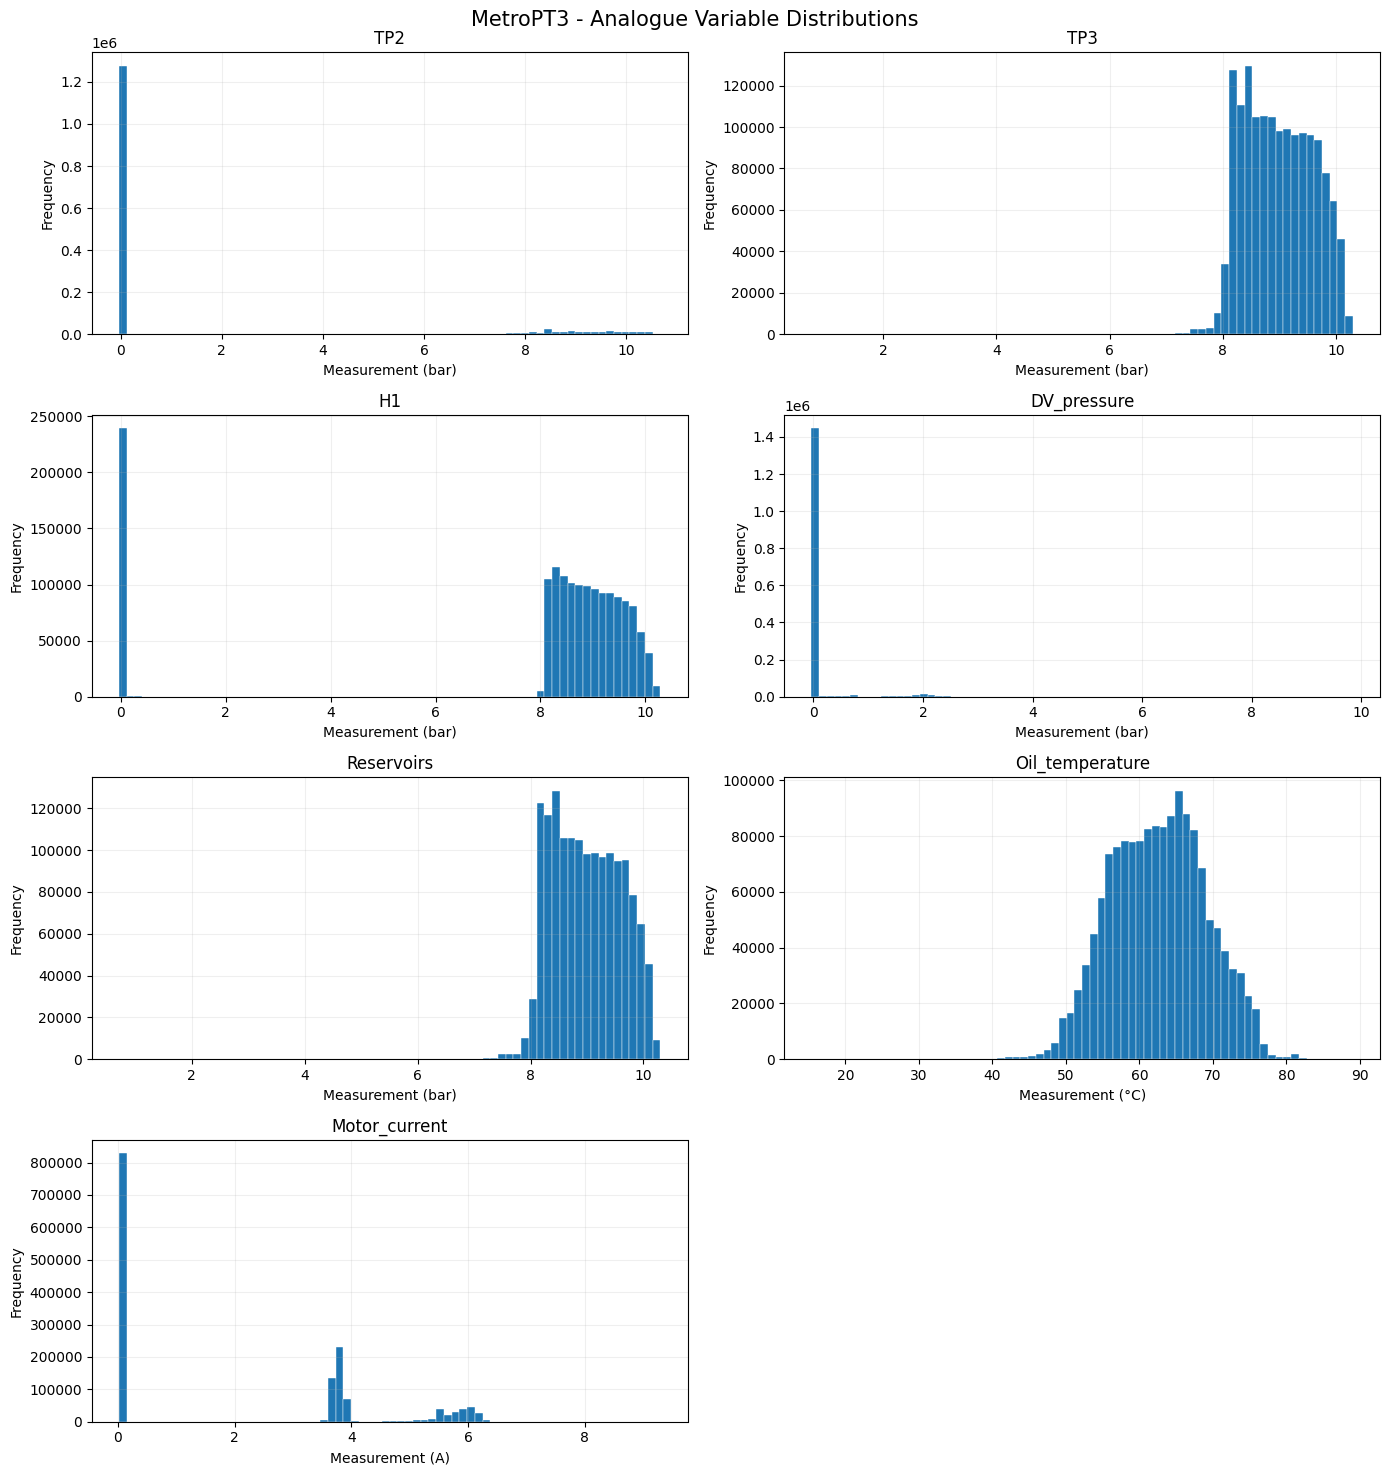

In [18]:
# 6.2.1 - Histograms of analogue variables

units = {
    "TP2": "bar",
    "TP3": "bar",
    "H1": "bar",
    "DV_pressure": "bar",
    "Reservoirs": "bar",
    "Oil_temperature": "°C",
    "Motor_current": "A"
}

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 15)
)

axes = axes.flatten()

for i, col in enumerate(analog_vars):
    axes[i].hist(
        df_analysis[col],
        bins=70,
        edgecolor="white",
        linewidth=0.3
    )

    axes[i].set_title(col)
    axes[i].set_xlabel(
        f"Measurement ({units[col]})"
    )
    axes[i].set_ylabel("Frequency")
    axes[i].grid(alpha=0.2)

axes[-1].axis("off")

plt.suptitle(
    "MetroPT3 - Analogue Variable Distributions",
    fontsize=15
)

plt.tight_layout()

plt.show()

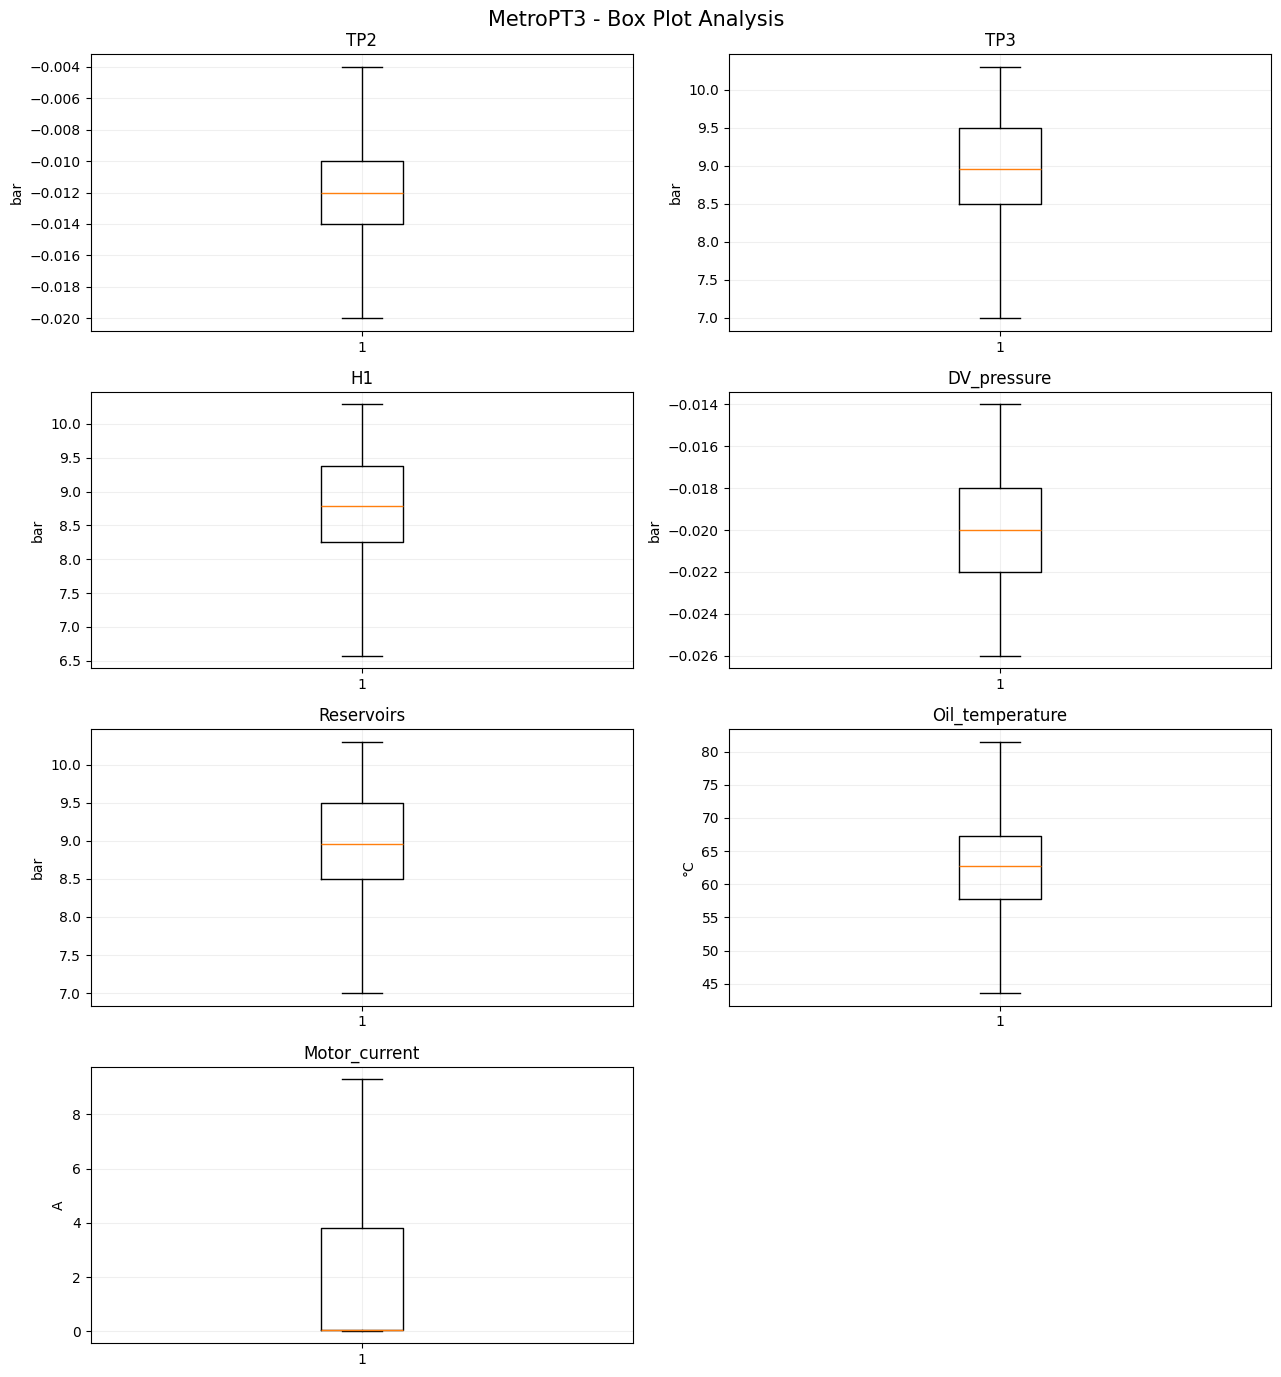

,Variable,Lower_fence,Upper_fence,Flagged_records,Flagged_percent
0,TP2,-0.020,-0.004,269592,17.772
1,TP3,6.992,10.992,4518,0.298
2,H1,6.574,11.054,241327,15.909
3,DV_pressure,-0.028,-0.012,113111,7.456
4,Reservoirs,6.997,10.989,4526,0.298
5,Oil_temperature,43.562,81.463,5194,0.342
6,Motor_current,-5.611,9.459,0,0.000


In [19]:
# 6.2.2 - Box plots for analogue variables

fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 14)
)

axes = axes.flatten()

for i, col in enumerate(analog_vars):
    axes[i].boxplot(
        df_analysis[col].dropna(),
        vert=True,
        showfliers=False
    )

    axes[i].set_title(col)
    axes[i].set_ylabel(units[col])
    axes[i].grid(alpha=0.2)

axes[-1].axis("off")

plt.suptitle(
    "MetroPT3 - Box Plot Analysis",
    fontsize=15
)

plt.tight_layout()
plt.show()

# IQR-based descriptive flags
outlier_results = []

for col in analog_vars:
    q1 = df_analysis[col].quantile(0.25)
    q3 = df_analysis[col].quantile(0.75)

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flags = (
        (df_analysis[col] < lower)
        | (df_analysis[col] > upper)
    )

    outlier_results.append({
        "Variable": col,
        "Lower_fence": lower,
        "Upper_fence": upper,
        "Flagged_records": int(flags.sum()),
        "Flagged_percent": (
            flags.mean() * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(3))

In [20]:
# 6.3.1 - Daily descriptive aggregation

temporal_data = df_analysis.set_index(
    "timestamp"
).sort_index()

daily_variables = [
    "Oil_temperature",
    "Motor_current",
    "TP3",
    "Reservoirs"
]

daily_summary = (
    temporal_data[daily_variables]
    .resample("D")
    .agg(["mean", "median", "min", "max", "count"])
)

print("DAILY DESCRIPTIVE SUMMARY")
print("-" * 50)

display(daily_summary.head(10))

print("Calendar days represented:",
      len(daily_summary))

print("Days with oil-temperature observations:",
      int(
          daily_summary[
              ("Oil_temperature", "count")
          ].gt(0).sum()
      ))

DAILY DESCRIPTIVE SUMMARY
--------------------------------------------------


Oil_temperature                               Motor_current  \
                      mean  median     min     max count          mean   
timestamp                                                                
2020-02-01       55.748117  56.075  44.850  64.075  7144      1.292689   
2020-02-02       55.820082  56.525  31.975  62.325  7031      1.382803   
2020-02-03       56.088392  56.225  49.000  61.650  8716      1.135509   
2020-02-04       55.033116  55.700  46.625  64.175  8717      1.240221   
2020-02-05       57.026489  57.225  42.250  65.200  7437      1.425138   
2020-02-06       56.655193  57.200  35.275  64.575  4939      1.245672   
2020-02-07       58.957416  59.075  37.725  69.150  7052      1.390153   
2020-02-08       58.627336  58.675  52.700  68.125  8689      1.498592   
2020-02-09       58.045903  58.375  47.325  66.125  7279      1.299397   
2020-02-10       55.811640  56.000  47.500  64.400  7468      1.194134   

                                               TP3                        \
            median     min     max count      mean median    min     max   
timestamp                                                                  
2020-02-01  0.0400  0.0300  6.3750  7144  8.968314  8.938  7.892  10.150   
2020-02-02  0.0375  0.0325  7.3575  7031  8.983974  8.968  7.588  10.156   
2020-02-03  0.0375  0.0325  6.8675  8716  8.946111  8.910  8.042  10.136   
2020-02-04  0.0375  0.0275  6.3625  8717  8.954529  8.914  7.738  10.146   
2020-02-05  0.0375  0.0275  6.3975  7437  8.987058  8.964  7.846  10.148   
2020-02-06  0.0375  0.0250  6.3900  4939  8.973693  8.950  7.380  10.158   
2020-02-07  0.0375  0.0200  6.3875  7052  8.985738  8.970  7.324  10.164   
2020-02-08  0.0375  0.0300  8.2925  8689  8.981182  8.972  7.632  10.144   
2020-02-09  0.0375  0.0300  6.3275  7279  8.947625  8.918  7.354  10.138   
2020-02-10  0.0375  0.0250  6.3575  7468  8.976054  8.972  7.928  10.144   

                 Reservoirs                              
           count       mean median    min     max count  
timestamp                                                
2020-02-01  7144   8.970930  8.941  7.894  10.148  7144  
2020-02-02  7031   8.986492  8.970  7.596  10.158  7031  
2020-02-03  8716   8.948008  8.912  8.044  10.136  8716  
2020-02-04  8717   8.956433  8.916  7.740  10.146  8717  
2020-02-05  7437   8.989430  8.966  7.846  10.148  7437  
2020-02-06  4939   8.976489  8.952  7.382  10.160  4939  
2020-02-07  7052   8.988902  8.972  7.326  10.168  7052  
2020-02-08  8689   8.983195  8.974  7.632  10.146  8689  
2020-02-09  7279   8.950514  8.920  7.358  10.142  7279  
2020-02-10  7468   8.978069  8.976  7.928  10.144  7468

Calendar days represented: 214
Days with oil-temperature observations: 212


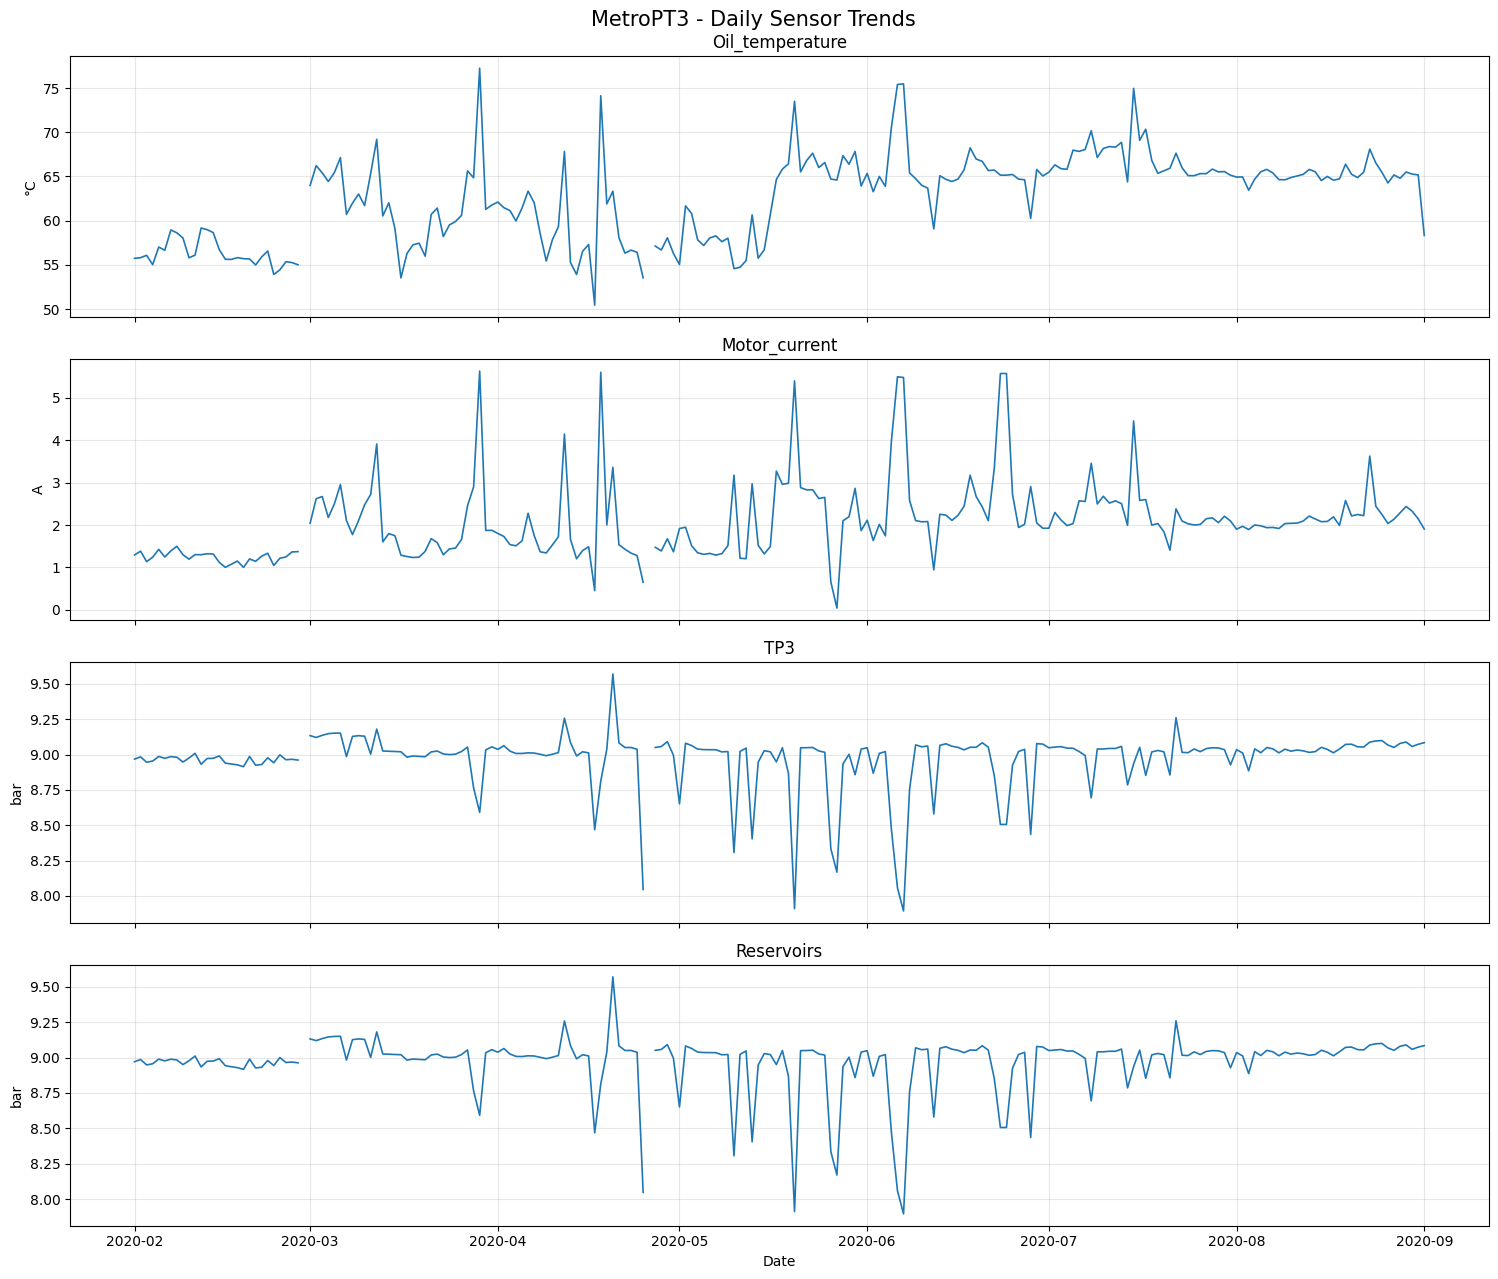

In [21]:
# 6.3.2 - Daily temporal trends

trend_variables = [
    "Oil_temperature",
    "Motor_current",
    "TP3",
    "Reservoirs"
]

daily_means = (
    temporal_data[trend_variables]
    .resample("D")
    .mean()
)

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 13),
    sharex=True
)

for ax, col in zip(axes, trend_variables):
    ax.plot(
        daily_means.index,
        daily_means[col],
        linewidth=1.2
    )

    ax.set_title(col)
    ax.set_ylabel(units[col])
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

plt.suptitle(
    "MetroPT3 - Daily Sensor Trends",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [22]:
# 6.4.1 - Pearson and Spearman correlations

pearson_matrix = (
    df_analysis[analog_vars]
    .corr(method="pearson")
)

spearman_matrix = (
    df_analysis[analog_vars]
    .corr(method="spearman")
)

print("PEARSON CORRELATION MATRIX")
display(pearson_matrix.round(3))

print("SPEARMAN CORRELATION MATRIX")
display(spearman_matrix.round(3))

PEARSON CORRELATION MATRIX


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
TP2,1.000,-0.011,-0.961,0.415,-0.012,0.251,0.697
TP3,-0.011,1.000,0.225,-0.153,1.000,0.402,0.414
H1,-0.961,0.225,1.000,-0.426,0.226,-0.162,-0.600
DV_pressure,0.415,-0.153,-0.426,1.000,-0.153,0.340,0.302
Reservoirs,-0.012,1.000,0.226,-0.153,1.000,0.402,0.413
Oil_temperature,0.251,0.402,-0.162,0.340,0.402,1.000,0.529
Motor_current,0.697,0.414,-0.600,0.302,0.413,0.529,1.000


SPEARMAN CORRELATION MATRIX


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
TP2,1.000,0.004,-0.391,0.550,0.004,0.357,0.358
TP3,0.004,1.000,0.728,-0.058,1.000,0.433,0.453
H1,-0.391,0.728,1.000,-0.149,0.729,0.253,0.008
DV_pressure,0.550,-0.058,-0.149,1.000,-0.057,0.438,0.024
Reservoirs,0.004,1.000,0.729,-0.057,1.000,0.434,0.452
Oil_temperature,0.357,0.433,0.253,0.438,0.434,1.000,0.494
Motor_current,0.358,0.453,0.008,0.024,0.452,0.494,1.000


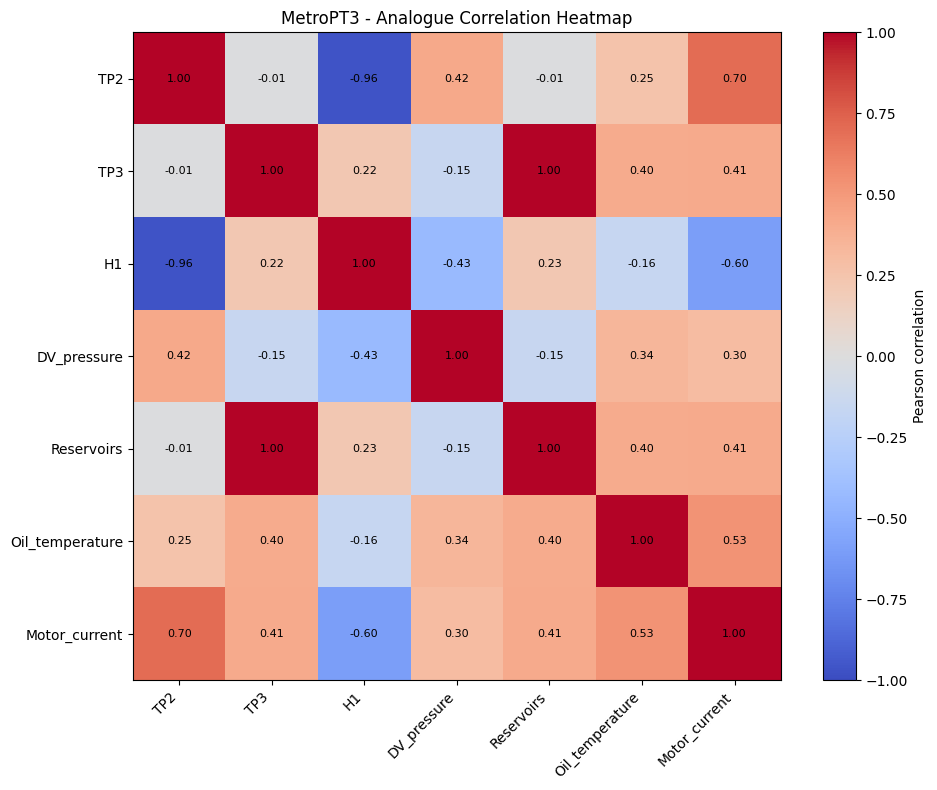

In [23]:
# 6.4.2 - Pearson correlation heatmap

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    pearson_matrix,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(analog_vars)))
ax.set_yticks(range(len(analog_vars)))

ax.set_xticklabels(
    analog_vars,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(analog_vars)

for i in range(len(analog_vars)):
    for j in range(len(analog_vars)):
        ax.text(
            j, i,
            f"{pearson_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(
    im,
    ax=ax,
    label="Pearson correlation"
)

ax.set_title(
    "MetroPT3 - Analogue Correlation Heatmap"
)

plt.tight_layout()
plt.show()

In [24]:
# 6.5.1 - Digital state frequencies

state_summary = pd.DataFrame({
    "Zero_count": (
        df_analysis[digital_vars] == 0
    ).sum(),
    "One_count": (
        df_analysis[digital_vars] == 1
    ).sum(),
    "One_percent": (
        df_analysis[digital_vars].mean() * 100
    )
})

print("DIGITAL OPERATING STATE FREQUENCIES")
print("-" * 50)

display(state_summary.round(2))

DIGITAL OPERATING STATE FREQUENCIES
--------------------------------------------------


,Zero_count,One_count,One_percent
COMP,247328,1269620,83.70
DV_eletric,1273310,243638,16.06
Towers,121586,1395362,91.98
MPG,253840,1263108,83.27
LPS,1511760,5188,0.34
Pressure_switch,12990,1503958,99.14
Oil_level,145391,1371557,90.42
Caudal_impulses,95406,1421542,93.71


In [25]:
# 6.5.2 - Analogue behavior by operating signal

comparison_vars = [
    "Motor_current",
    "Oil_temperature",
    "TP3",
    "Reservoirs"
]

for signal in ["DV_eletric", "COMP"]:

    print(f"\nOPERATING SIGNAL: {signal}")
    print("-" * 50)

    grouped = (
        df_analysis
        .groupby(signal)[comparison_vars]
        .agg(["count", "mean", "median", "std"])
    )

    display(grouped.round(3))

# Complementary analysis: COMP vs DV_eletric

state_combinations = pd.crosstab(
    df_analysis["COMP"],
    df_analysis["DV_eletric"],
    margins=True
)

display(state_combinations)


OPERATING SIGNAL: DV_eletric
--------------------------------------------------


Motor_current                      Oil_temperature                  \
                   count   mean median    std           count    mean  median   
DV_eletric                                                                      
0                1273310  1.356  0.042  1.793         1273310  61.955  62.075   
1                 243638  5.681  5.835  0.696          243638  66.244  65.900   

                       TP3                     Reservoirs                       
              std    count   mean median   std      count   mean median    std  
DV_eletric                                                                      
0           5.962  1273310  9.007  8.972  0.57    1273310  9.007  8.974  0.570  
1           7.946   243638  8.870  8.866  0.91     243638  8.869  8.864  0.909


OPERATING SIGNAL: COMP
--------------------------------------------------


Motor_current                      Oil_temperature                  \
             count   mean median    std           count    mean  median   
COMP                                                                      
0           247328  5.604  5.828  1.014          247328  66.094  65.575   
1          1269620  1.358  0.042  1.787         1269620  61.972  62.075   

                 TP3                      Reservoirs                       
        std    count   mean median    std      count   mean median    std  
COMP                                                                       
0     7.961   247328  8.835  8.796  0.898     247328  8.834  8.794  0.897  
1     5.968  1269620  9.014  8.982  0.571    1269620  9.015  8.984  0.570

DV_eletric,0,1,All
COMP,,,
0,10226,237102,247328
1,1263084,6536,1269620
All,1273310,243638,1516948


In [26]:
# 6.6.1 - Documented air-leak event intervals

events = [
    (
        "Event_1",
        "2020-04-18 00:00:00",
        "2020-04-18 23:59:00"
    ),
    (
        "Event_2",
        "2020-05-29 23:30:00",
        "2020-05-30 06:00:00"
    ),
    (
        "Event_3",
        "2020-06-05 10:00:00",
        "2020-06-07 14:30:00"
    ),
    (
        "Event_4",
        "2020-07-15 14:30:00",
        "2020-07-15 19:00:00"
    )
]

event_data = df_analysis.copy()

event_data["Documented_event"] = "Outside_event"

for label, start, end in events:

    mask = event_data["timestamp"].between(
        pd.Timestamp(start),
        pd.Timestamp(end),
        inclusive="both"
    )

    event_data.loc[
        mask, "Documented_event"
    ] = label

event_counts = (
    event_data["Documented_event"]
    .value_counts()
    .rename_axis("Event_period")
    .reset_index(name="Observations")
)

print("DOCUMENTED EVENT PERIODS")
print("-" * 50)

display(event_counts)

DOCUMENTED EVENT PERIODS
--------------------------------------------------


,Event_period,Observations
0,Outside_event,1486994
1,Event_3,17315
2,Event_1,8657
3,Event_2,2360
4,Event_4,1622


In [27]:
# 6.6.2 - Descriptive comparison of event periods

event_variables = [
    "Motor_current",
    "Oil_temperature",
    "TP3",
    "Reservoirs"
]

event_summary = (
    event_data.groupby(
        "Documented_event"
    )[event_variables]
    .agg(["count", "mean", "median", "std"])
)

print("EVENT PERIOD DESCRIPTIVE COMPARISON")
print("-" * 50)

display(event_summary.round(3))

EVENT PERIOD DESCRIPTIVE COMPARISON
--------------------------------------------------


Motor_current                      Oil_temperature          \
                         count   mean median    std           count    mean   
Documented_event                                                              
Event_1                   8657  5.604  5.708  0.599            8657  74.131   
Event_2                   2360  5.566  5.613  0.224            2360  75.871   
Event_3                  17315  5.494  5.528  0.154           17315  75.517   
Event_4                   1622  5.510  5.515  0.448            1622  83.906   
Outside_event          1486994  1.980  0.045  2.270         1486994  62.383   

                                     TP3                      Reservoirs  \
                  median    std    count   mean median    std      count   
Documented_event                                                           
Event_1           74.225  2.809     8657  8.812  8.834  0.114       8657   
Event_2           76.075  0.552     2360  8.402  8.378  0.168       2360   
Event_3           75.550  1.529    17315  8.018  8.078  0.286      17315   
Event_4           84.600  3.248     1622  8.207  8.216  1.132       1622   
Outside_event     62.550  6.300  1486994  8.999  8.978  0.634    1486994   

                                       
                   mean median    std  
Documented_event                       
Event_1           8.813  8.836  0.114  
Event_2           8.404  8.380  0.168  
Event_3           8.020  8.082  0.286  
Event_4           8.205  8.215  1.132  
Outside_event     8.999  8.980  0.633